## EE512 – Applied Biomedical Signal Processing
# Practical session – Linear Models II
### Instructions
* This notebook provides all the questions of the practical session and the space to answer them. We recommend working directly here and then exporting the document as your report.
* Include any code used when addressing the questions, any figures you find useful, together with your answers.
* Please submit your report as a single PDF file, named according to: `name1_name2_name3_LabLinearModelsI.pdf`.
* We recommend working in a group of 4–5 students (max 6); the report does not have to be submitted by every group member -- one submission per group is sufficient.

In [155]:
%matplotlib widget

# Imports
import os
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import resample, welch, correlate
from statsmodels.regression.linear_model import yule_walker
from statsmodels.tsa.ar_model import AutoReg

# File paths
fhr1 = os.path.join(os.getcwd(), 'data', 'heart_1.dat')
fhr2 = os.path.join(os.getcwd(), 'data', 'heart_2.dat')
fem1 = os.path.join(os.getcwd(), 'data', 'emg1.dat')
fem2 = os.path.join(os.getcwd(), 'data', 'emg2.dat')
fppg = os.path.join(os.getcwd(), 'data', 'ppg.dat')
feeg = os.path.join(os.getcwd(), 'data', 'eeg_stim.dat')

### Experiment 1: parametric spectral estimation of cardiorespiratory signals
The file `/data/heart_1.dat` contains three physiological signals: RR-interval, arterial pressure and respiration, in this order (sampled at 4 Hz). The recordings were made in a patient at rest. In the spectral domain, this RR-interval signal is expected to show a peak around 0.08 Hz, corresponding to the *baroreflex* (regulation between arterial blood pressure and heart rate), and a peak at 0.225 Hz, corresponding to the *breathing rate* (heart rhythm modulation by respiration, the so-called *“sinus arrhythmia”*) – see `/data/readme_heart.txt` for more details.

We start by importing the signals, subsampling to 1 Hz, and removing their averages:

In [156]:
with open(fhr1, 'r') as f:
    txt = f.readlines()
    txt = [s[:-1].split() for s in txt]
    
    rr1 = np.array([float(s[0]) for s in txt])
    bp1 = np.array([float(s[1]) for s in txt])
    rs1 = np.array([float(s[2]) for s in txt])

df = 4
rr1 = resample(rr1, int(len(rr1)/df))
bp1 = resample(bp1, int(len(bp1)/df))
rs1 = resample(rs1, int(len(rs1)/df))

for y in [rr1, bp1, rs1]:
    y -= np.mean(y)

AR modeling provides tools for extracting various useful estimates from a signal, in a so-called *parametric* way, because the estimates are based on the model parameters, rather than on the raw signal itself. The function defined below implements the estimation of the signal spectral density based on its AR parameters.

In [157]:
def ar_psd(arg1, arg2, arg3, n=1000):
    """
    Parametric spectral density estimation based on AR modeling
    
    Inputs:
        arg1: ?
        arg2: ?
        arg3: ?
        n: defines the spectral sampling
    
    Outputs:
        arg4: ?
        arg5: ?
    """
    
    arg5 = np.arange(n) * arg3/2/n
    aar, sg = yule_walker(arg1, order=arg2, method="mle")
    
    a = complex(1)
    for k in range(1,arg2+1):
        a += -aar[k-1] * np.exp(-2*np.pi*k*1j*arg5/arg3)
    
    arg4 = sg**2 / (arg3 * np.abs(a)**2)
    
    return arg4, arg5

**Question 1.1.** The implementation above has an incomplete docstring (help text), and the input and output arguments have generic names (`arg1-5`). Copy the function to the answer space below, complete the help, and replace the argument names by more intuitive choices, based on what you've learned in the theory.

**Answer 1.1.** `Write your answer here`

We now use this tool to obtain the spectral density of the three signals. Below, we explore the results obtained with different AR model orders: 5, 15, 40.

/var/folders/jw/wp0rwhl95mn5p3zty_bgbcdc0000gn/T/ipykernel_9906/3111342998.py:17: FutureWarning: yule_walker currently returns a plain tuple whose length depends on the inv argument. In release 0.16 or after July 2028, whichever is later, the default behavior will switch to returning a YuleWalkerResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  aar, sg = yule_walker(arg1, order=arg2, method="mle")


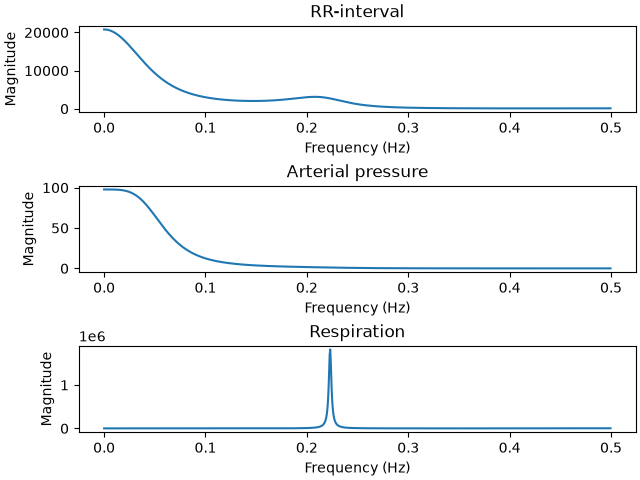

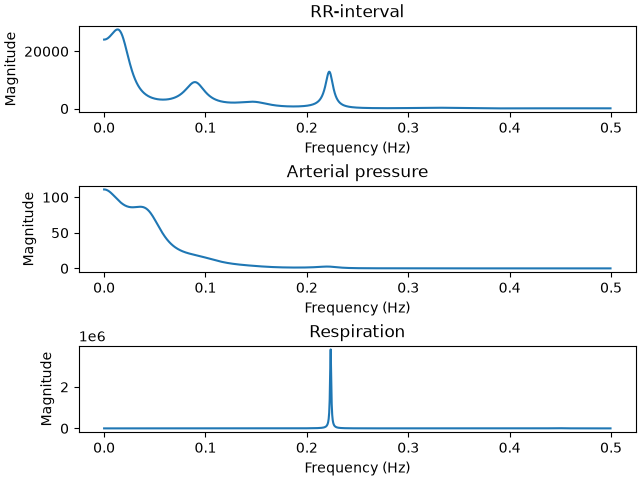

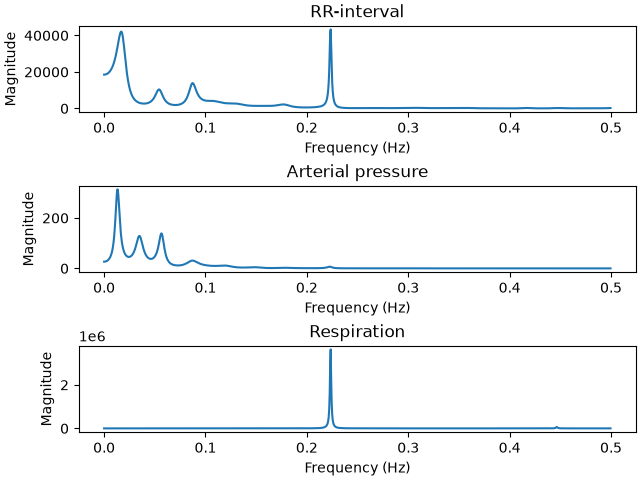

In [158]:
y = [rr1, bp1, rs1]
ttl = ['RR-interval', 'Arterial pressure', 'Respiration']

for p in (5, 15, 40):
    
    plt.figure(constrained_layout=True)
    
    for k in range(3):
        
        py, f = ar_psd(y[k], p, 1.0)
        
        plt.subplot(3,1,k+1)
        plt.plot(f, py)
        plt.xlabel('Frequency (Hz)')
        plt.ylabel('Magnitude')
        plt.title(ttl[k])

**Question 1.2.** How does the order affect the spectra? Given the physiological description of the expected peaks for the RR-interval, what is the most suitable order choice?

**Answer 1.2.** `Write your answer here`

We can now perform a *non-parametric* spectral estimation of the same signals, using for instance Welch’s method:

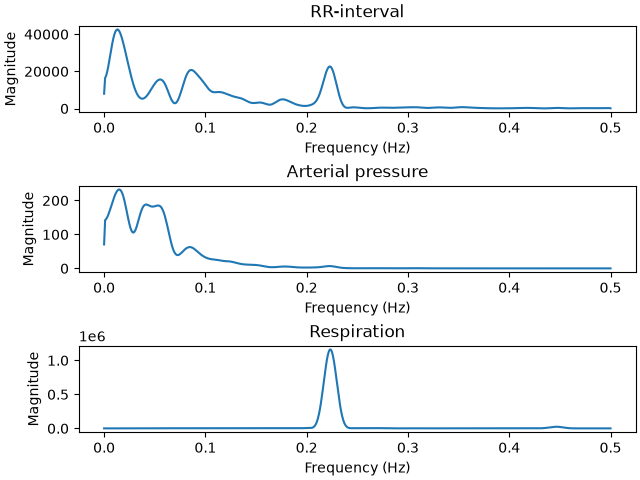

In [159]:
y = [rr1, bp1, rs1]
ttl = ['RR-interval', 'Arterial pressure', 'Respiration']

plt.figure(constrained_layout=True)

for k in range(3):
    
    f, py = welch(y[k], fs=1.0, nperseg=100, scaling='density', nfft=1000)
    
    plt.subplot(3,1,k+1)
    plt.plot(f, py)
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.title(ttl[k])

**Question 1.3.** In our particular problem, how do the spectra obtained with Welch's method compare with those of the parametric approach (order 15)? Given the previous RR-interval description, which approach performs most reliably?

**Answer 1.3.** `Write your answer here`

We now consider the signals in `/data/heart_2.dat`, which are recordings from the same individual after alcohol consumption.

In [160]:
with open(fhr2, 'r') as f:
    txt = f.readlines()
    txt = [s[:-1].split() for s in txt]
    
    rr2 = np.array([float(s[0]) for s in txt])
    bp2 = np.array([float(s[1]) for s in txt])
    rs2 = np.array([float(s[2]) for s in txt])

**Question 1.4.** Repeat the processing steps done for `heart_1.dat` to obtain a parametric spectral estimation (order 15). Which of the physiological mechanisms described for the RR-interval was most disrupted by alcohol? And what other changes do you observe in the physiological signals?

**Answer 1.4.** `Write your answer here`

### Experiment 2: estimating the effects of fatigue on muscle signals
The files `/data/emg1.dat` and `/data/emg2.dat` contain three surface electromyography (sEMG) signals each (1024 Hz sampling frequency). These signals were recorded from the thigh muscle during a 10-min exercise on an ergocycle, respectively from an athlete (`emg1`) and from a moderately trained subject (`emg2`). In each file, the columns correspond to recordings from the *start*, *middle* and *end* of the exercise, respectively.

We start by importing the signals:

In [161]:
with open(fem1, 'r') as f:
    txt = f.readlines()
    txt = [s[:-1].split() for s in txt]
    
    n = len(txt)
    em1 = np.zeros((n,3))
    for k in range(3):
        em1[:,k] = [float(s[k]) for s in txt]

with open(fem2, 'r') as f:
    txt = f.readlines()
    txt = [s[:-1].split() for s in txt]
    
    n = len(txt)
    em2 = np.zeros((n,3))
    for k in range(3):
        em2[:,k] = [float(s[k]) for s in txt]

fs = 1024.0 # Hz

We first plot the sEMG segments in the time domain. We can observe four bursts in each recording, which correspond to four pedal strokes. The goal of the experiment was to assess the effects of fatigue on the signal properties of the sEMG.

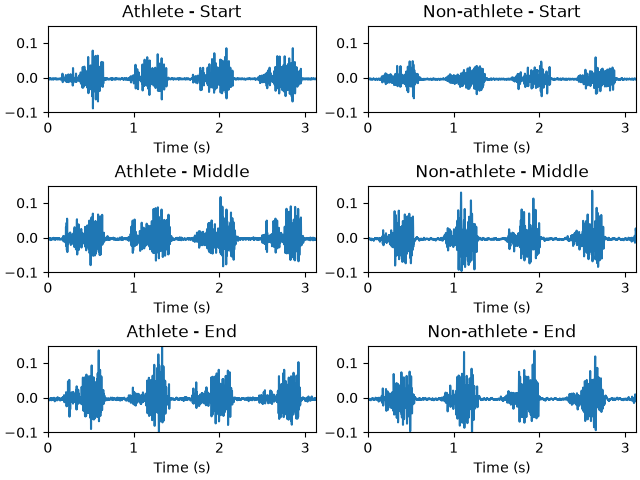

In [162]:
ttl1 = ['Athlete', 'Non-athlete']
ttl2 = ['Start', 'Middle', 'End']
t = np.arange(n) / fs

plt.figure(constrained_layout=True)
for k in range(2):
    
    y = [em1, em2][k]
    
    for l in range(3):
        
        plt.subplot(3,2,2*l+k+1)
        plt.plot(t,y[:,l])
        plt.xlim(t[0], t[-1])
        plt.ylim(-0.10, 0.15)
        plt.xlabel('Time (s)')
        plt.title(ttl1[k] + ' - ' + ttl2[l])

We'll now look at the spectral profile of the signals. Considering, for instance, the start sEMG recording of the athlete, we obtain the parametric power spectral density (PSD) for an AR model of order 30:

/var/folders/jw/wp0rwhl95mn5p3zty_bgbcdc0000gn/T/ipykernel_9906/3111342998.py:17: FutureWarning: yule_walker currently returns a plain tuple whose length depends on the inv argument. In release 0.16 or after July 2028, whichever is later, the default behavior will switch to returning a YuleWalkerResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  aar, sg = yule_walker(arg1, order=arg2, method="mle")


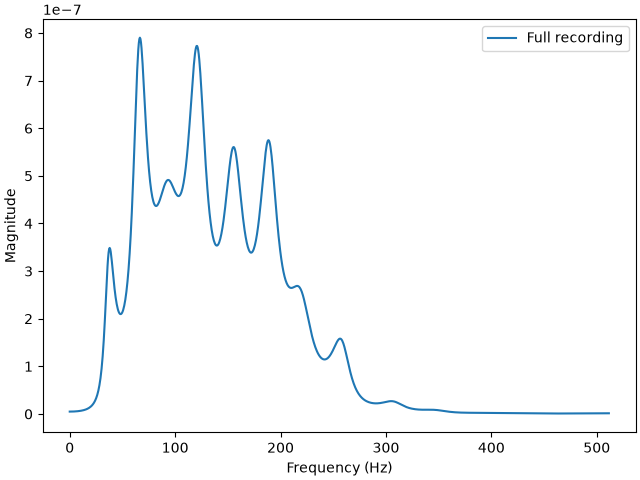

In [163]:
p = 30
pya, fa = ar_psd(em1[:,0], p, fs)

plt.figure(constrained_layout=True)
plt.plot(fa, pya, label='Full recording')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.legend()

**Question 2.1.** In principle, it would be more correct to segment each burst and analyze it separately, but it turns out that using the entire recording will yield a relatively similar spectral profile. Check that it is the case: copy the plotting code above to the space below and add (overlayed in the same panel) the PSD obtained from the first burst only, for the same signal. How do their profiles compare? Where does the difference in peak signal-to-noise come from?

**Answer 2.1.** `Write your answer here`

We now estimate and plot the PSD for every recorded segment of both individuals:

/var/folders/jw/wp0rwhl95mn5p3zty_bgbcdc0000gn/T/ipykernel_9906/3111342998.py:17: FutureWarning: yule_walker currently returns a plain tuple whose length depends on the inv argument. In release 0.16 or after July 2028, whichever is later, the default behavior will switch to returning a YuleWalkerResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  aar, sg = yule_walker(arg1, order=arg2, method="mle")


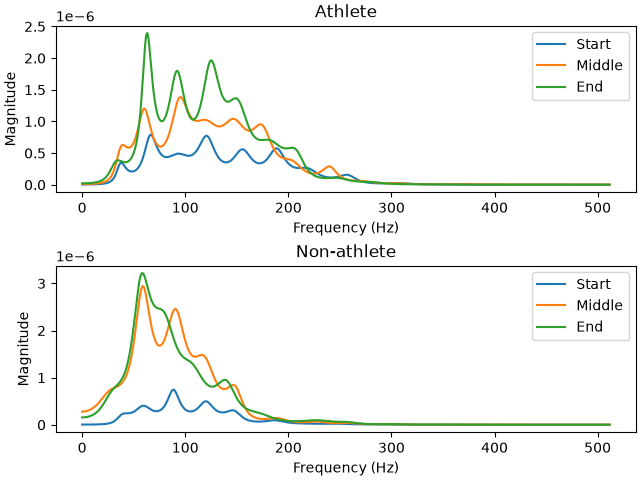

In [164]:
plt.figure(constrained_layout=True)
for k in range(2):
    
    y = [em1, em2][k]
    plt.subplot(2,1,k+1)
    
    for l in range(3):
        
        pya, fa = ar_psd(y[:,l], p, fs)
        plt.plot(fa, pya, label=ttl2[l])
        plt.xlabel('Frequency (Hz)')
        plt.ylabel('Magnitude')
    
    plt.title(ttl1[k])
    plt.legend()

**Question 2.2.** To complement the above PSD's, estimate the mean frequency using `sum(fa * pya / sum(pya))`. What does this formula express?

**Answer 2.2.** `Write your answer here`

**Question 2.3.** Based on the PSD plots and the mean frequencies obtained above, what marks the difference between the athlete and the moderately trained subject?

**Answer 2.3.** `Write your answer here`

### Experiment 3: assessment of PPG signal structure
Photoplethysmography (PPG) is a simple, low-cost, non-invasive optical monitoring technique that can be used to detect volumetric changes in blood in the peripheral circulation, by measuring on the skin surface. It can be integrated in wearable devices (e.g. a watch) to monitor a person’s heart rate throughout daily life, and detect potential issues like atrial fibrillation. The file `/data/ppg.dat` contains a PPG recording from a normal cardiac rhythm, and another from a subject in atrial fibrillation (both sampled at 21.3 Hz).

We start by importing and plotting the two signals:

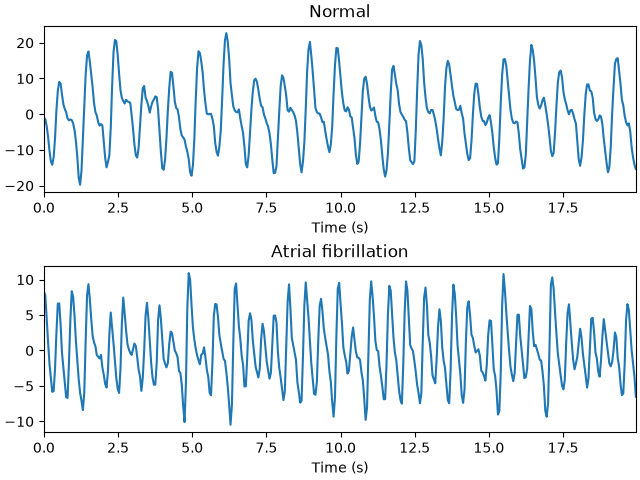

In [165]:
with open(fppg, 'r') as f:
    txt = f.readlines()
    txt = [s[:-1].split() for s in txt]
    
    ppg1 = np.array([float(s[0]) for s in txt])
    ppg2 = np.array([float(s[1]) for s in txt])

for y in [ppg1, ppg2]:
    y -= np.mean(y)

fs = 21.3 # Hz

plt.figure(constrained_layout=True)
ttl = ['Normal', 'Atrial fibrillation']

n = len(ppg1)
t = np.arange(n) / fs

for k in range(2):
    
    y = [ppg1, ppg2][k]
    
    plt.subplot(2,1,k+1)
    plt.plot(t, y)
    plt.xlim(t[0], t[-1])
    plt.xlabel('Time (s)')
    plt.title(ttl[k])

Each observed oscillation on the PPG typically corresponds to one pulse, generated by one cardiac cycle. By inspecting the plot above, we can already appreciate how one signal is visibly less regular than the other. AR modeling allows us to quantify the underlying differences with several complementary metrics.

We define again the function `ar_order` introduced in the previous practical session:

In [166]:
def ar_order(x, omax, Aff=0):
    """
    AR order estimation
    x: signal
    omax: maximum possible order
    Aff: 0 no graphic display; 1 display
    
    Returns:
    omdl: order estimated with MDL
    """
    
    nx = len(x)
    s = np.zeros((omax,))
    c = np.zeros((omax,))

    for k in range(omax):
        
        n = k+1
        
        ar_model = AutoReg(x, n, trend='n')
        ar_model_fit = ar_model.fit()
        sg2 = ar_model_fit.sigma2
        
        s[k] = sg2
        c[k] = nx * np.log(sg2) + (n+1) * np.log(nx)

    if Aff == 1:
        plt.figure()
        plt.plot(range(1, omax+1), c, 'o-')
        plt.title('Criterion')
        plt.show()
        
    return np.argmin(c)+1, s, c

**Question 3.1.** Estimate the optimal AR model order for each signal, using the function `ar_order` above (you can set a maximal order of 40 for the search).

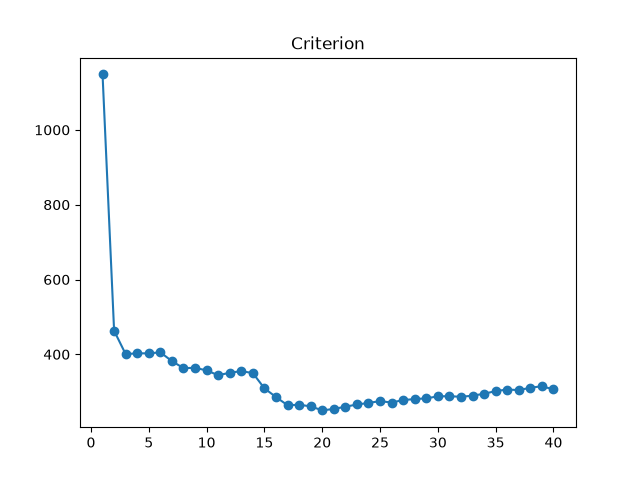

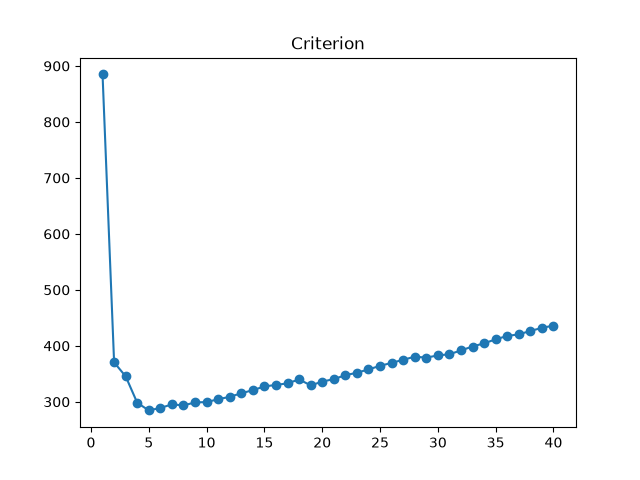

The optimal order for the normal ppg is 20 and the optimal order for the fibrillation signal is 5


In [167]:
#using ar_order to estimate optimal AR model order for the normal ppg signal
opt_ar_order_normal = ar_order(ppg1, 40, 1)[0]
plt.title('MDL criterion – Normal PPG')

#using ar_order to estimate optimal AR model order for the atrial fibrillation ppg signal
opt_ar_order_fibr = ar_order(ppg2, 40, 1)[0]
plt.title('MDL criterion – fibrillation PPG')
print("The optimal order for the normal ppg is", opt_ar_order_normal, "and the optimal order for the fibrillation signal is", opt_ar_order_fibr)

**Answer 3.1.** 

Using the MDL criterion (maximum order 40), the optimal AR order is 20 for the normal PPG and 5 for the atrial fibrillation PPG.

**Question 3.2.** Estimate the ratio between the excitation variance and the signal variance, for each signal (as in previous exercises, you can rely on the `yule_walker` function with `method='mle'`)

In [168]:
# Normal PPG: fit AR model with its optimal order and compute the variance ratio
normal_coeffs, normal_sigma = yule_walker(ppg1, order=opt_ar_order_normal, method='mle', result_object=False)
e_var_normal = normal_sigma**2          # excitation variance
var_normal = np.var(ppg1)               # signal variance, r(0)
ratio_normal = e_var_normal / var_normal

# AF PPG: same procedure with its own optimal order
fibr_coeffs, fibr_sigma = yule_walker(ppg2, order=opt_ar_order_fibr, method='mle', result_object=False)
e_var_fibr = fibr_sigma**2
var_fibr = np.var(ppg2)
ratio_fibr = e_var_fibr / var_fibr

print(f"Normal PPG (order {opt_ar_order_normal}): excitation/signal variance ratio = {ratio_normal:.4f}")
print(f"AF PPG (order {opt_ar_order_fibr}): excitation/signal variance ratio = {ratio_fibr:.4f}")

Normal PPG (order 20): excitation/signal variance ratio = 0.0277
AF PPG (order 5): excitation/signal variance ratio = 0.1087


**Answer 3.2.** 

Using the optimal orders from 3.1, the ratio is 0.028 for the normal PPG (order 20) and 0.109 for the AF PPG (order 5). The AR model therefore leaves about 4 times (0.109/0.028) more unexplained power in the AF signal than in the normal one.

**Question 3.3.** Estimate and plot the PSD of each signal, using the `ar_psd` function for the estimates (for consistency, use the same order of 20 for both signals)

/var/folders/jw/wp0rwhl95mn5p3zty_bgbcdc0000gn/T/ipykernel_9906/3111342998.py:17: FutureWarning: yule_walker currently returns a plain tuple whose length depends on the inv argument. In release 0.16 or after July 2028, whichever is later, the default behavior will switch to returning a YuleWalkerResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  aar, sg = yule_walker(arg1, order=arg2, method="mle")


Text(0.5, 1.0, 'Atrial fibrillation PPG – AR PSD (order 20)')

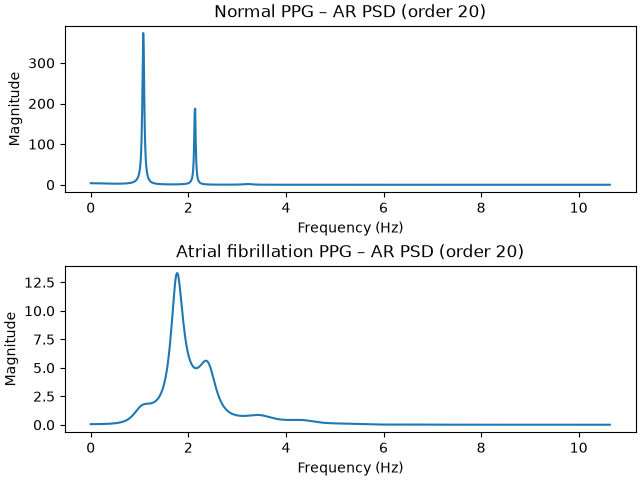

In [169]:
#same order of 20 for both signals
order = 20

# fs = 21.3 Hz was set in the import cell

# Estimating PSD for each signal
psd_normal, f_normal = ar_psd(ppg1, order, fs)
psd_fibr, f_fibr = ar_psd(ppg2, order, fs)

# Plotting PSD for each signal
plt.figure(constrained_layout=True)

plt.subplot(2, 1, 1)
plt.plot(f_normal, psd_normal)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Normal PPG – AR PSD (order 20)')

plt.subplot(2, 1, 2)
plt.plot(f_fibr, psd_fibr)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Atrial fibrillation PPG – AR PSD (order 20)')

**Answer 3.3.**

For the normal PPG, the PSD plot shows two very sharp peaks: at ≈1.1 Hz (the heart rate, ≈65 bpm) and at ≈2.2 Hz (2nd harmonic). The PSD is ≈0 everywhere else. 
The power is concentrated at two frequencies, which indicates a very regular signal (healthy regular heartbeats). 

For the AF PPG, the main peak is at ≈1.8 Hz (≈108 bpm, a faster rhythm). It is much wider and lower. 
The power is spread over a broad band (≈1-4 Hz) with no clear harmonic, which indicates an irregular signal (atrial fibrillation irregular heartbeats). The heart rate keeps varying, so the power is distributed over many frequencies.

**Question 3.4.** Estimate the entropy of the PSD of each signal, using:

*p = py / sum(py)*

*entropy = sum(-p * log(p))*

where py is the vector of PSD amplitudes.

In [170]:
#entropy function
def entropy(py):
    p = py / np.sum(py)
    entropy = sum(-p * np.log(p))
    return entropy

#entropy of the normal PSD
entropy_normal = entropy(psd_normal)

#entropy of the fibrillation PSD
entropy_fibr = entropy(psd_fibr)

print(f"Spectral entropy – Normal PPG: {entropy_normal:.3f}")
print(f"Spectral entropy – AF PPG: {entropy_fibr:.3f}")

Spectral entropy – Normal PPG: 4.007
Spectral entropy – AF PPG: 5.504


**Answer 3.4.**

The spectral entropy is 4.01 for the normal PPG and 5.50 for the AF PPG. 

The normal PPG has lower entropy than the fibrillation PPG because its power is concentrated in a few sharp peaks, while the power for AF is spread over a wider band of frequencies.

**Question 3.5.** What do these measures (model order, variance ratio, PSD, entropy) tell us about the two signals? Interpret what you have obtained in terms of signal structure/organization.

**Answer 3.5.**

All four measures consistently show that the normal PPG is a highly organised, predictable signal, while the AF PPG is much less structured:
- **Model order (20 vs 5):** the normal PPG has a rich, repeating structure (fundamental + harmonic) that needs many AR coefficients to be described. For the AF PPG, extra coefficients do not improve the model, because there is little regular structure to capture.
- **Variance ratio (0.028 vs 0.109):** the AR model predicts ≈97% of the normal signal’s power but leaves ≈4× more unpredictable power in the AF signal.
- **PSD:** the normal PPG concentrates its power in sharp peaks at the heart rate (≈1.1 Hz) and its harmonic, while the AF PPG shows a broad, low peak (≈1.8 Hz) with power spread over ≈1–4 Hz.
- **Entropy (4.01 vs 5.50):** the higher entropy of the AF PSD confirms that its power is more spread out, i.e. less organised.

Overall, the normal PPG reflects a regular cardiac rhythm with consistent beat intervals, whereas the AF PPG reflects the irregular intervals characteristic of atrial fibrillation. 

Therefore, these results could be used to automatically detect AF from a wearable PPG sensor.

### Experiment 4: Pisarenko harmonic estimation of brain signals
The file `/data/eeg_stim.dat` contains three recordings of scalp electroencephalography (EEG; left frontal electrode, 4-s duration, 512 Hz sampling frequency) from a Parkinson's patient. The patient was also implanted with a deep brain stimulation (DBS) electrode. The first recording corresponds to a baseline (rest) state, the second was obtained during 1-Hz stimulation, and the third during 100-Hz stimulation.

We start by importing and plotting the three signals:

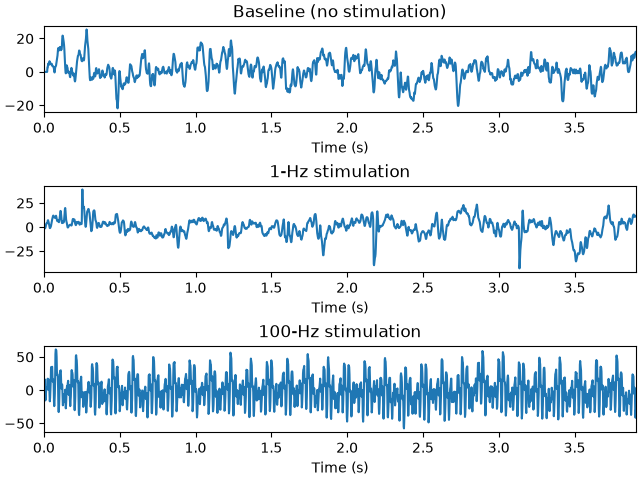

In [171]:
with open(feeg, 'r') as f:
    txt = f.readlines()
    txt = [s[:-1].split() for s in txt]
    
    n = len(txt)
    eeg = np.zeros((n,3))
    for k in range(3):
        eeg[:,k] = [float(s[k]) for s in txt]

fs = 512.0 # Hz

plt.figure(constrained_layout=True)
ttl = ['Baseline (no stimulation)', '1-Hz stimulation', '100-Hz stimulation']

t = np.arange(n) / fs

for k in range(3):
    plt.subplot(3,1,k+1)
    plt.plot(t, eeg[:,k])
    plt.xlim(t[0], t[-1])
    plt.xlabel('Time (s)')
    plt.title(ttl[k])

**Question 4.1.** Visually, does any of the stimulation strategies appear to have an effect on the EEG? Which one(s)?

**Answer 4.1.** `Write your answer here`

As in previous examples, we can apply modeling techniques to quantify the physiological effects under study. Because the DBS is applied in a periodic regime with a specific frequency, it is reasonable to expect a strong sinusoidal presence on the EEG recordings, for any cases where the stimulation does produce a measurable effect. This motivates applying the Pisarenko harmonic retrieval approach, which is implemented below:

In [172]:
def pisarenko(x, p, fs, Aff=0):
    """
    Pisarenko method for harmonic retrieval
    
    x: signal
    p: number of sinusoids
    fs: sampling frequency
    Aff: 0 no graphic display; 1 display
    
    f: vector of sinusoid frequencies
    pp: vector of sinusoid amplitudes
    sg2: noise variance
    
    """
    
    n = len(x)
    
    rx = correlate(x, x, mode='full', method='auto') / n
    
    rxx = np.zeros((2*p+1,2*p+1))
    for k1 in range(2*p+1):
        for k2 in range(2*p+1):
            rxx[k1,k2] = rx[n-1 + abs(k1 - k2)]
    
    u, v = np.linalg.eig(rxx)
    
    sg2 = np.min(u)
    vm = v[:,np.argmin(u)]  # get eigenvector from smallest eigenvalue
    
    r = np.roots(vm)  # find roots of the polynomial
    f = np.angle(r) / (2*np.pi)  # get angle and convert to Hz/sample
    f = f[f > 0]
    
    # Amplitude estimation
    aa = np.zeros((p, len(f)))
    for k in range(p):
        aa[k,:] = np.cos(2*np.pi * (k+1) * f)
    
    r = rx[n:n+p]
    
    pp = np.linalg.lstsq(aa, r, rcond=None)[0]
    f *= fs
    
    if Aff:
        
        plt.figure(constrained_layout=True)
        
        plt.subplot(2,1,1)
        plt.plot(np.arange(1,n+1) / fs, x)
        plt.xlabel('Time (s)')
        plt.title('Signal')
        
        plt.subplot(2,1,2)
        plt.plot([0, fs/2], [sg2, sg2], linewidth=2)
        for k in range(p):
            plt.plot([f[k], f[k]], [sg2, sg2+pp[k]], linewidth=2)
        plt.axis([0, fs/2, 0, 1.2 * (np.max(pp) + sg2)])
        plt.xlabel('Frequency (Hz)')
        plt.title('Pisarenko spectrum')
    
    return f, pp, sg2

**Question 4.2.** Using the above function, apply the Pisarenko method with 5 sinusoids to each of the three recordings, and report the estimated parameters (frequencies, amplitudes, excitation variance).

**Answer 4.2.** `Write your answer here`

**Question 4.3.** Interpret the estimation results -- which stimulation frequency appears to effectively influence brain activity?

**Answer 4.3.** `Write your answer here`

### Have a good session, and don't hesitate to ask questions!